In [1]:
import tensorflow as tf

gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

2026-07-05 15:50:19.508814: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1783259419.528258   47100 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1783259419.534030   47100 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-07-05 15:50:19.553399: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

In [2]:
import tensorflow_datasets as tfds
dataset, ds_info = tfds.load(name="cycle_gan/vangogh2photo", with_info=True, as_supervised=False)
train_vangogh, train_real = dataset["trainA"], dataset["trainB"]
test_vangogh, test_real = dataset["testA"], dataset["testB"]

I0000 00:00:1783259424.214148   47100 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 7096 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1070, pci bus id: 0000:01:00.0, compute capability: 6.1


In [3]:
import tensorflow as tf

for name, ds in dataset.items():
    print(f"Number of images in {name}: {tf.data.experimental.cardinality(ds).numpy()}")

Number of images in trainA: 400
Number of images in trainB: 6287
Number of images in testA: 400
Number of images in testB: 751


2026-07-05 15:50:28.174896: I tensorflow/core/kernels/data/tf_record_dataset_op.cc:376] The default buffer size is 262144, which is overridden by the user specified `buffer_size` of 8388608
2026-07-05 15:50:28.224382: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


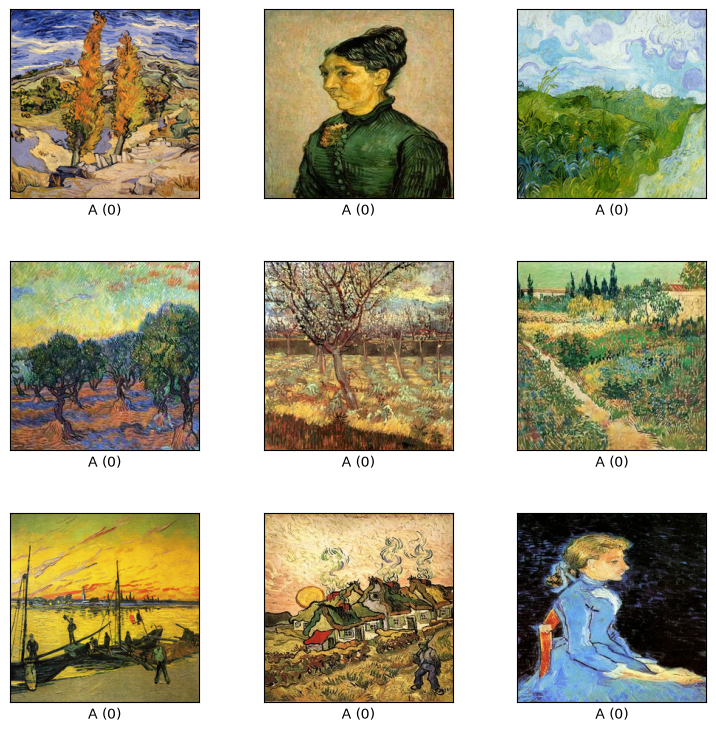

In [4]:
fig = tfds.show_examples(train_vangogh, ds_info)

2026-07-05 15:50:28.699291: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


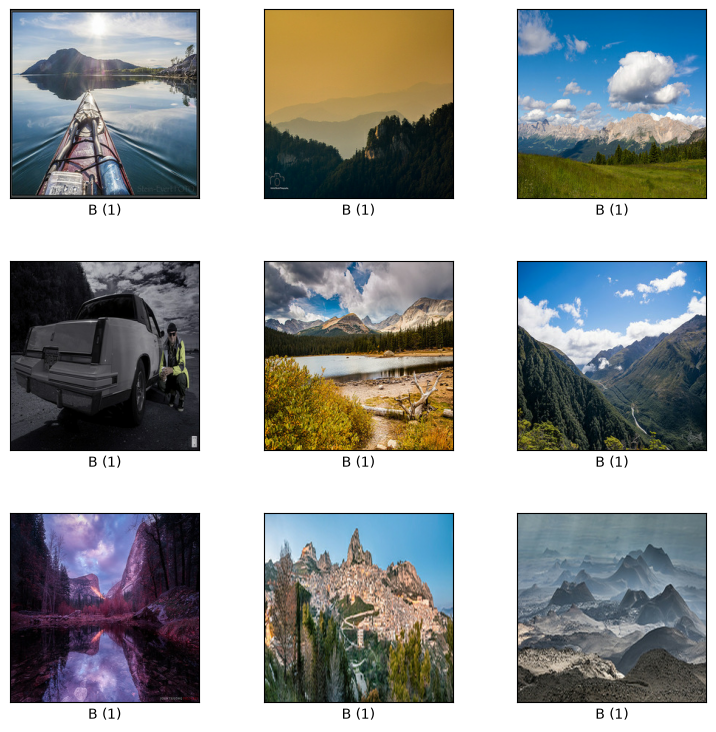

In [5]:
fig = tfds.show_examples(train_real, ds_info)

In [6]:
for example in train_real.take(1):
    print(f"Image dimensions: {example['image'].shape}")

Image dimensions: (256, 256, 3)


In [7]:
for example in train_vangogh.take(1):
    print(f"Image dimensions: {example['image'].shape}")

Image dimensions: (256, 256, 3)


2026-07-05 15:50:29.741514: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [8]:
train_vangogh.take(1)

<_TakeDataset element_spec={'image': TensorSpec(shape=(None, None, 3), dtype=tf.uint8, name=None), 'label': TensorSpec(shape=(), dtype=tf.int64, name=None)}>

In [9]:
import os
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt

import tensorflow as tf
from keras.layers import Input
from keras.models import Model, Sequential
from keras.layers import (
    Input,
    LeakyReLU,
    ReLU,
    BatchNormalization,
    Conv2DTranspose,
    Conv2D,
    concatenate,
    GroupNormalization,
    Activation,
    Add
)
from keras.optimizers import Adam

In [10]:
gpus = tf.config.experimental.list_physical_devices('GPU')

if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("Memory growth enabled for GPU")
    except RuntimeError as e:
        print(f"Error setting memory growth: {e}")

Memory growth enabled for GPU


In [12]:
BATCH_SIZE = 1
IMG_SIZE = (256, 256)

In [13]:
def preprocess_image(image):
    image = tf.cast(image['image'], tf.float32)
    image = (image - 127.5) / 127.5
    return image

In [14]:
train_A = train_vangogh.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE).cache().batch(BATCH_SIZE).prefetch(buffer_size=tf.data.AUTOTUNE)
train_B = train_real.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE).cache().batch(BATCH_SIZE).prefetch(buffer_size=tf.data.AUTOTUNE)

In [15]:
kernel_init = tf.keras.initializers.RandomNormal(mean=0.0, stddev=0.02)
gamma_init = tf.keras.initializers.RandomNormal(mean=0.0, stddev=0.02)

In [16]:
def residual_block(x, filters):
    shortcut = x
    y = Conv2D(filters, (3,3), padding="same",use_bias=False,kernel_initializer=kernel_init)(x)
    y = GroupNormalization(groups=-1, gamma_initializer=gamma_init)(y)
    y = Activation("relu")(y)

    y = Conv2D(filters, (3,3), padding="same",use_bias=False,kernel_initializer=kernel_init)(y)
    y = GroupNormalization(groups=-1, gamma_initializer=gamma_init)(y)

    return Add()([shortcut, y])

def build_generator(input_shape=(256,256,3), output_channels=3, n_res_blocks=9):

    inputs = Input(shape=input_shape)

    x = Conv2D(32, (7,7), padding="same",use_bias=False,kernel_initializer=kernel_init)(inputs)
    x = GroupNormalization(groups=-1, gamma_initializer=gamma_init)(x)
    x = Activation("relu")(x)

    x = Conv2D(64, (3,3), strides=2, padding="same",use_bias=False,kernel_initializer=kernel_init)(x)
    x = GroupNormalization(groups=-1, gamma_initializer=gamma_init)(x)
    x = Activation("relu")(x)

    x = Conv2D(128, (3,3), strides=2, padding="same",use_bias=False,kernel_initializer=kernel_init)(x)
    x = GroupNormalization(groups=-1, gamma_initializer=gamma_init)(x)
    x = Activation("relu")(x)

    for _ in range(n_res_blocks):
        x = residual_block(x, 128)

    x = Conv2DTranspose(64, (3,3), strides=2, padding="same",use_bias=False,kernel_initializer=kernel_init)(x)
    x = GroupNormalization(groups=-1, gamma_initializer=gamma_init)(x)
    x = Activation("relu")(x)

    x = Conv2DTranspose(32, (3,3), strides=2, padding="same",use_bias=False,kernel_initializer=kernel_init)(x)
    x = GroupNormalization(groups=-1, gamma_initializer=gamma_init)(x)
    x = Activation("relu")(x)

    outputs = Conv2D(output_channels, (7,7), padding="same", activation="tanh",use_bias=False)(x)

    return Model(inputs=inputs, outputs=outputs, name="ResNet_Generator_CycleGAN")

In [17]:
def build_discriminator(input_shape=(256,256,3)):
    inputs = Input(shape=input_shape)

    x = Conv2D(32, (4,4), strides=2, padding="same")(inputs)
    x = LeakyReLU(alpha=0.2)(x)

    x = Conv2D(64, (4,4), strides=2, padding="same")(x)
    x = GroupNormalization(groups=-1)(x)
    x = LeakyReLU(alpha=0.2)(x)

    x = Conv2D(128, (4,4), strides=2, padding="same")(x)
    x = GroupNormalization(groups=-1)(x)
    x = LeakyReLU(alpha=0.2)(x)

    x = Conv2D(256, (4,4), strides=2, padding="same")(x)
    x = GroupNormalization(groups=-1)(x)
    x = LeakyReLU(alpha=0.2)(x)

    outputs = Conv2D(1, (4,4), padding="same")(x)

    return Model(inputs=inputs, outputs=outputs, name="PatchGAN_Discriminator")

In [18]:
generator_A2B = build_generator(input_shape=IMG_SIZE + (3,), output_channels=3)
generator_B2A = build_generator(input_shape=IMG_SIZE + (3,), output_channels=3)

In [19]:
generator_A2B.summary()

Model: "ResNet_Generator_CycleGAN"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │      4,704 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalization │ (None, 256, 256,  │         64 │ conv2d[0][0]      │
│ (GroupNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 256, 256,  │          0 │ group_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │     18,432 │ activation[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_1[0][0]    │
│ (GroupNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 128, 128,  │          0 │ group_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     73,728 │ activation_1[0][… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_2[0][0]    │
│ (GroupNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 64, 64,    │          0 │ group_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │    147,456 │ activation_2[0][… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_3[0][0]    │
│ (GroupNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 64, 64,    │          0 │ group_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │    147,456 │ activation_3[0][… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_4[0][0]    │
│ (GroupNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 64, 64,    │          0 │ activation_2[0][… │
│                     │ 128)              │            │ group_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 64, 64,    │    147,456 │ add[0][0]       

 Total params: 2,853,184 (10.88 MB)

 Trainable params: 2,853,184 (10.88 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:
discriminator_A = build_discriminator(input_shape=IMG_SIZE + (3,))
discriminator_B = build_discriminator(input_shape=IMG_SIZE + (3,))

/home/armin/miniconda3/envs/tf-gpu/lib/python3.11/site-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


In [21]:
discriminator_A.summary()

Model: "PatchGAN_Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_44 (Conv2D)              │ (None, 128, 128, 32)   │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_45 (Conv2D)              │ (None, 64, 64, 64)     │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_normalization_46          │ (None, 64, 64, 64)     │           128 │
│ (GroupNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_46 (Conv2D)              │ (None, 32, 32, 128)    │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_normalization_47          │ (None, 32, 32, 128)    │           256 │
│ (GroupNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_47 (Conv2D)              │ (None, 16, 16, 256)    │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_normalization_48          │ (None, 16, 16, 256)    │           512 │
│ (GroupNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_48 (Conv2D)              │ (None, 16, 16, 1)      │         4,097 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 695,137 (2.65 MB)

 Trainable params: 695,137 (2.65 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
def plotGeneratedImages(model, test_input, epoch, direction):
    prediction = model(test_input, training=False)

    if direction == "A2B":
        cycled_input = generator_B2A(prediction, training=False)
    else:
        cycled_input = generator_A2B(prediction, training=False)

    plt.figure(figsize=(8, 8))

    display_list = [test_input[0], prediction[0], cycled_input[0]]
    title = ['Original Image', 'Translated Image', 'Cycled Image']

    for i in range(3):
        plt.subplot(1, 3, i + 1)
        plt.title(title[i])
        plt.imshow(display_list[i] * 0.5 + 0.5)
        plt.axis('off')

    output_dir = './cyclegan_generated_images/'
    os.makedirs(output_dir, exist_ok=True)
    plt.savefig(f'{output_dir}/epoch_{epoch}_{direction}.png')
    plt.close()

In [23]:
INITIAL_LR = 0.0002
DECAY_START_EPOCH = 90
TOTAL_EPOCHS = 150

def learning_rate_scheduler(epoch):

    if epoch < DECAY_START_EPOCH:
        return INITIAL_LR
    else:
        decay_epochs = TOTAL_EPOCHS - DECAY_START_EPOCH
        decay_rate = INITIAL_LR / decay_epochs

        new_lr = INITIAL_LR - (epoch - DECAY_START_EPOCH) * decay_rate

        return max(new_lr, 0.0)

In [24]:
generator_A2B_optimizer = Adam(beta_1=0.5)
generator_B2A_optimizer = Adam(beta_1=0.5)
discriminator_A_optimizer = Adam(beta_1=0.5)
discriminator_B_optimizer = Adam(beta_1=0.5)

mse_loss = tf.keras.losses.MeanSquaredError() #MSE 
mae_loss = tf.keras.losses.MeanAbsoluteError() #MAE

def discriminator_loss(real, generated):
    real_loss = mse_loss(tf.ones_like(real), real)
    generated_loss = mse_loss(tf.zeros_like(generated), generated)
    total_disc_loss = real_loss + generated_loss
    return total_disc_loss

# LSGAN: Least-Squares Loss
def generator_loss(generated):
    return mse_loss(tf.ones_like(generated), generated)

def cycle_consistency_loss(real_image, cycled_image):
    loss = mae_loss(real_image, cycled_image)
    return 10.0 * loss

def identity_loss(real_image, same_image):
    loss = mae_loss(real_image, same_image)
    return 5.0 * loss

In [25]:
@tf.function(jit_compile=True)
def train_step(real_A, real_B):
    with tf.GradientTape(persistent=True) as tape:
        fake_B = generator_A2B(real_A, training=True)
        cycled_A = generator_B2A(fake_B, training=True)

        fake_A = generator_B2A(real_B, training=True)
        cycled_B = generator_A2B(fake_A, training=True)

        same_A = generator_B2A(real_A, training=True)
        same_B = generator_A2B(real_B, training=True)

        disc_real_A = discriminator_A(real_A, training=True)
        disc_real_B = discriminator_B(real_B, training=True)

        disc_fake_A = discriminator_A(fake_A, training=True)
        disc_fake_B = discriminator_B(fake_B, training=True)

        gen_A2B_loss = generator_loss(disc_fake_B)
        gen_B2A_loss = generator_loss(disc_fake_A)

        total_cycle_loss = cycle_consistency_loss(real_A, cycled_A) + cycle_consistency_loss(real_B, cycled_B)

        id_loss_A = identity_loss(real_A, same_A)
        id_loss_B = identity_loss(real_B, same_B)

        total_gen_A2B_loss = gen_A2B_loss + total_cycle_loss + id_loss_B
        total_gen_B2A_loss = gen_B2A_loss + total_cycle_loss + id_loss_A

        disc_A_loss = discriminator_loss(disc_real_A, disc_fake_A)
        disc_B_loss = discriminator_loss(disc_real_B, disc_fake_B)

    discriminator_A_gradients = tape.gradient(disc_A_loss, discriminator_A.trainable_variables)
    discriminator_B_gradients = tape.gradient(disc_B_loss, discriminator_B.trainable_variables)
    discriminator_A_optimizer.apply_gradients(zip(discriminator_A_gradients, discriminator_A.trainable_variables))
    discriminator_B_optimizer.apply_gradients(zip(discriminator_B_gradients, discriminator_B.trainable_variables))

    generator_A2B_gradients = tape.gradient(total_gen_A2B_loss, generator_A2B.trainable_variables)
    generator_B2A_gradients = tape.gradient(total_gen_B2A_loss, generator_B2A.trainable_variables)
    generator_A2B_optimizer.apply_gradients(zip(generator_A2B_gradients, generator_A2B.trainable_variables))
    generator_B2A_optimizer.apply_gradients(zip(generator_B2A_gradients, generator_B2A.trainable_variables))

    return total_gen_A2B_loss, total_gen_B2A_loss, disc_A_loss, disc_B_loss

In [26]:
epochs = 120

history = {
    "G_A2B": [], "G_B2A": [], "D_A": [], "D_B": []
}

for e in range(1, epochs + 1):
    epoch_gen_A2B_losses = []
    epoch_gen_B2A_losses = []
    epoch_disc_A_losses = []
    epoch_disc_B_losses = []

    new_learning_rate = learning_rate_scheduler(e)

    generator_A2B_optimizer.learning_rate.assign(new_learning_rate)
    generator_B2A_optimizer.learning_rate.assign(new_learning_rate)
    discriminator_A_optimizer.learning_rate.assign(new_learning_rate)
    discriminator_B_optimizer.learning_rate.assign(new_learning_rate)

    print('-' * 10, 'Epoch %d' % e, '-' * 10)
    print(f"Learning Rate for this epoch: {new_learning_rate}")

    for image_a, image_b in tqdm(tf.data.Dataset.zip((train_A, train_B))):
        total_gen_A2B_loss, total_gen_B2A_loss, disc_A_loss, disc_B_loss = train_step(image_a, image_b)

        epoch_gen_A2B_losses.append(total_gen_A2B_loss.numpy())
        epoch_gen_B2A_losses.append(total_gen_B2A_loss.numpy())
        epoch_disc_A_losses.append(disc_A_loss.numpy())
        epoch_disc_B_losses.append(disc_B_loss.numpy())


    avg_g_A2B = np.mean(epoch_gen_A2B_losses)
    avg_g_B2A = np.mean(epoch_gen_B2A_losses)
    avg_d_A = np.mean(epoch_disc_A_losses)
    avg_d_B = np.mean(epoch_disc_B_losses)

    history["G_A2B"].append(avg_g_A2B)
    history["G_B2A"].append(avg_g_B2A)
    history["D_A"].append(avg_d_A)
    history["D_B"].append(avg_d_B)

    print(f"  Avg Gen A->B Loss: {avg_g_A2B:.4f}")
    print(f"  Avg Gen B->A Loss: {avg_g_B2A:.4f}")
    print(f"  Avg Disc A Loss: {avg_d_A:.4f}")
    print(f"  Avg Disc B Loss: {avg_d_B:.4f}")

    if e == 1 or e % 10 == 0:
        sample_A = next(iter(train_A))
        sample_B = next(iter(train_B))
        plotGeneratedImages(generator_A2B, sample_A, e, "A2B")
        plotGeneratedImages(generator_B2A, sample_B, e, "B2A")

---------- Epoch 1 ----------
Learning Rate for this epoch: 0.0002


  0%|                                                                                  | 0/400 [00:00<?, ?it/s]WARNING: All log messages before absl::InitializeLog() is called are written to STDERR
I0000 00:00:1783259495.076968   47100 service.cc:148] XLA service 0x60ffbeacf2c0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1783259495.077000   47100 service.cc:156]   StreamExecutor device (0): NVIDIA GeForce GTX 1070, Compute Capability 6.1
2026-07-05 15:51:36.615163: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1783259501.254281   47100 cuda_dnn.cc:529] Loaded cuDNN version 90300
2026-07-05 15:51:50.943386: W external/local_xla/xla/service/gpu/nvptx_compiler.cc:930] The NVIDIA driver's CUDA version is 12.2 which is older than the PTX compiler version 12.5.82. Because the driver is older than the PTX compiler ve

  Avg Gen A->B Loss: 10.2019
  Avg Gen B->A Loss: 10.1527
  Avg Disc A Loss: 0.4302
  Avg Disc B Loss: 0.4294
---------- Epoch 2 ----------
Learning Rate for this epoch: 0.0002


100%|████████████████████████████████████████████████████████████████████████| 400/400 [00:59<00:00,  6.71it/s]


  Avg Gen A->B Loss: 7.7259
  Avg Gen B->A Loss: 7.8904
  Avg Disc A Loss: 0.2311
  Avg Disc B Loss: 0.3234
---------- Epoch 3 ----------
Learning Rate for this epoch: 0.0002


...

  Avg Gen A->B Loss: 3.5662
  Avg Gen B->A Loss: 3.6640
  Avg Disc A Loss: 0.2669
  Avg Disc B Loss: 0.2420
---------- Epoch 119 ----------
Learning Rate for this epoch: 0.00010333333333333334


100%|████████████████████████████████████████████████████████████████████████| 400/400 [01:06<00:00,  6.05it/s]


  Avg Gen A->B Loss: 3.5505
  Avg Gen B->A Loss: 3.6330
  Avg Disc A Loss: 0.2678
  Avg Disc B Loss: 0.2327
---------- Epoch 120 ----------
Learning Rate for this epoch: 0.0001


100%|████████████████████████████████████████████████████████████████████████| 400/400 [01:07<00:00,  5.96it/s]
2026-07-05 18:05:04.344939: W tensorflow/core/kernels/data/cache_dataset_ops.cc:914] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


  Avg Gen A->B Loss: 3.5613
  Avg Gen B->A Loss: 3.6376
  Avg Disc A Loss: 0.2610
  Avg Disc B Loss: 0.2341


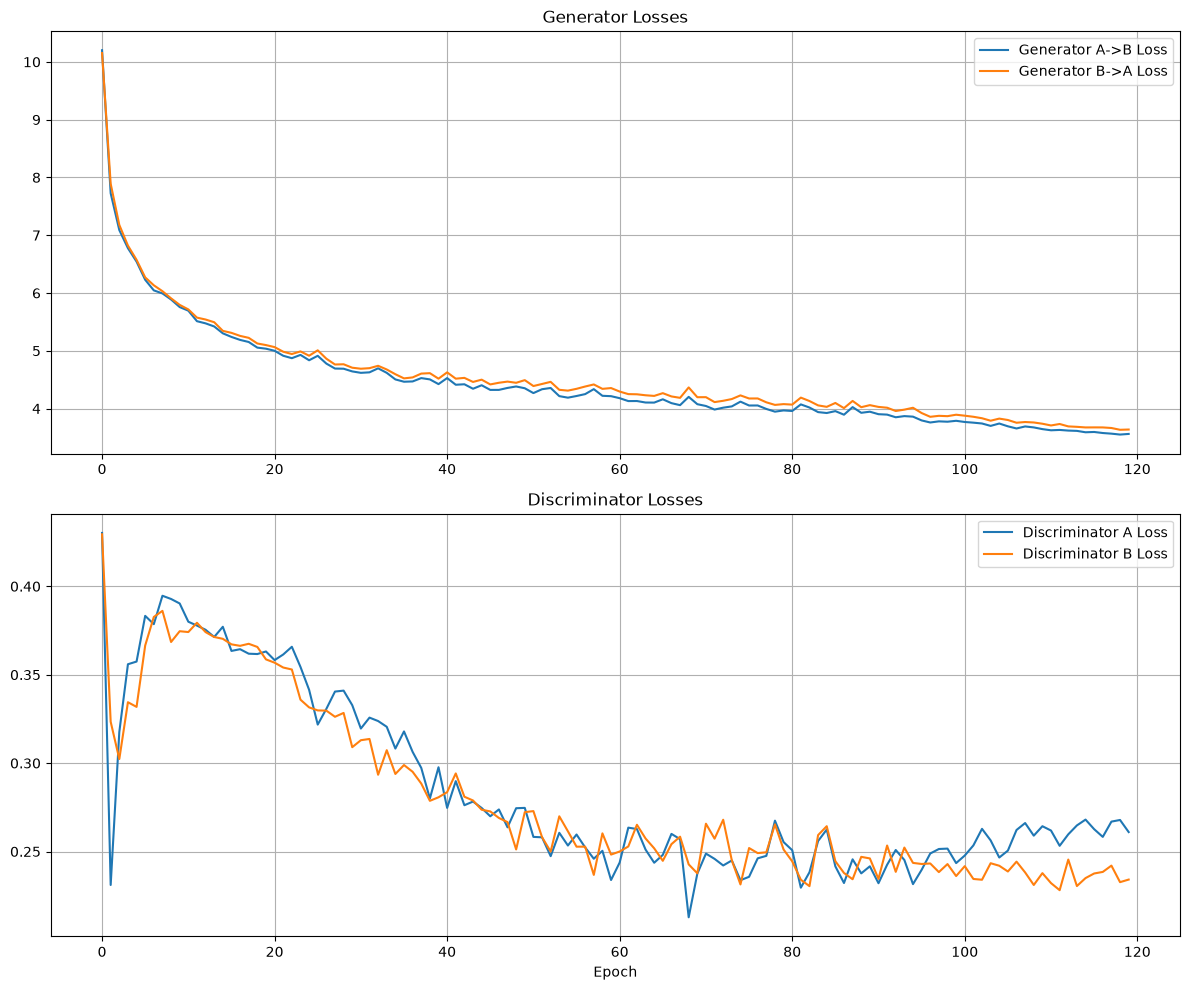

In [27]:
fig, axs = plt.subplots(2, 1, figsize=(12, 10))

axs[0].plot(history['G_A2B'], label='Generator A->B Loss')
axs[0].plot(history['G_B2A'], label='Generator B->A Loss')
axs[0].set_title('Generator Losses')
axs[0].legend()
axs[0].grid(True)

axs[1].plot(history['D_A'], label='Discriminator A Loss')
axs[1].plot(history['D_B'], label='Discriminator B Loss')
axs[1].set_title('Discriminator Losses')
axs[1].set_xlabel('Epoch')
axs[1].legend()
axs[1].grid(True)

plt.tight_layout()
plt.show()

In [28]:
# Save the generator models
generator_A2B.save('generator_A2B_model.keras')
generator_B2A.save('generator_B2A_model.keras')